# Customer Retention Intelligence — Baseline Modeling

## Objective
Train and evaluate **baseline** models for `churn_next_30_days` on the
leakage-safe feature dataset built in Phase 4
(`data/processed/customer_features.parquet`): a simple Logistic Regression
and a simple Random Forest, split **chronologically** by `snapshot_date`
(never randomly), with class-imbalance-appropriate metrics.

This notebook trains baselines only -- no hyperparameter tuning, threshold
optimization, SHAP, MLflow, or deployment. Those are later phases.

## Why chronological splitting
The whole point of this project is to predict the future from the past. A
random train/test split would let rows from the same or even a later month
than a test row sit in the training set, silently leaking information a
real production model would never have at prediction time. Splitting by
`snapshot_date` keeps training strictly earlier than validation, and
validation strictly earlier than test.


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

from src.models import baseline as bl

PROJECT_ROOT


PosixPath('/Users/dhananjaymandal/customer-retention-intelligence')

## 2. Load Feature Dataset

Loads `data/processed/customer_features.parquet` from Phase 4: 131 feature
columns plus `customer_id`, `snapshot_date`, and the target
`churn_next_30_days`.


In [2]:
features = bl.load_feature_dataset()
print("shape:", features.shape)
print("columns:", len(features.columns))
features.head()


shape: (136701, 134)
columns: 134


,customer_id,snapshot_date,age,country,plan,contract_type,acquisition_channel,tenure_days,tenure_months,txn_count_30d,txn_amount_sum_30d,txn_amount_mean_30d,txn_amount_max_30d,txn_success_count_30d,txn_failed_count_30d,...,high_critical_ticket_count_180d,avg_satisfaction_180d,min_satisfaction_180d,avg_resolution_hours_180d,max_resolution_hours_180d,category_account_count_180d,category_billing_count_180d,category_feature_request_count_180d,category_login_count_180d,category_other_count_180d,category_performance_count_180d,category_technical_count_180d,days_since_last_ticket,has_any_support_history,churn_next_30_days
0,C000001,2025-05-31,69,United States,Basic,Monthly,Referral,21,0.69,1.0,35.71,35.710,35.71,1.0,0.0,...,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,False,0
1,C000001,2025-06-30,69,United States,Basic,Monthly,Referral,51,1.68,1.0,28.20,28.200,28.20,1.0,0.0,...,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,False,0
2,C000001,2025-07-31,69,United States,Basic,Monthly,Referral,82,2.69,0.0,0.00,NaN,NaN,0.0,0.0,...,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,False,0
3,C000001,2025-08-31,69,United States,Basic,Monthly,Referral,113,3.71,1.0,37.69,37.690,37.69,1.0,0.0,...,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,False,0
4,C000001,2025-09-30,69,United States,Basic,Monthly,Referral,143,4.70,2.0,73.71,36.855,37.49,2.0,0.0,...,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,False,0


## 3. Time-Based Split

Chronological split on `snapshot_date`, aligned to the 17 monthly snapshots
from Phase 4:

| Split | Snapshot dates |
|---|---|
| Train | 2025-01-31 -> 2025-11-30 (11 snapshots) |
| Validation | 2025-12-31 -> 2026-02-28 (3 snapshots) |
| Test | 2026-03-31 -> 2026-05-31 (3 snapshots) |

`split_by_snapshot_date` raises if the windows are not strictly
chronological, and we additionally verify there is no overlap and no row
loss below.


In [3]:
splits = bl.split_by_snapshot_date(features)

assert sum(len(df) for df in splits.values()) == len(features), "Split lost or duplicated rows"

train_dates = set(splits["train"]["snapshot_date"])
validation_dates = set(splits["validation"]["snapshot_date"])
test_dates = set(splits["test"]["snapshot_date"])
assert train_dates.isdisjoint(validation_dates)
assert train_dates.isdisjoint(test_dates)
assert validation_dates.isdisjoint(test_dates)
assert max(train_dates) < min(validation_dates) < max(validation_dates) < min(test_dates)

print("No overlap between splits; row counts sum to the full dataset. Confirmed.")


No overlap between splits; row counts sum to the full dataset. Confirmed.


## 4. Target / Class Distribution

In [4]:
split_summary = pd.DataFrame([bl.summarize_split(name, df) for name, df in splits.items()])
split_summary


,split,rows,unique_customers,positive_count,negative_count,positive_pct,min_snapshot_date,max_snapshot_date
0,train,85419,9454,820,84599,0.960,2025-01-31,2025-11-30
1,validation,26337,8917,448,25889,1.701,2025-12-31,2026-02-28
2,test,24945,8478,402,24543,1.612,2026-03-31,2026-05-31


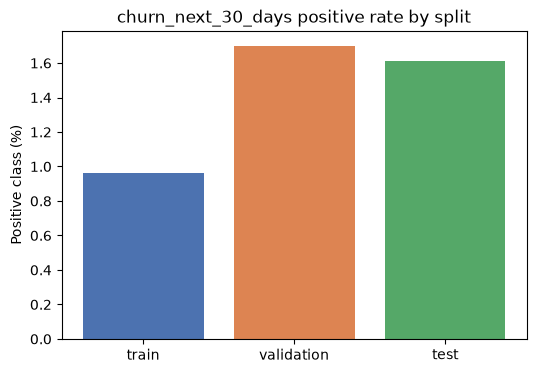

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(split_summary["split"], split_summary["positive_pct"], color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_ylabel("Positive class (%)")
ax.set_title("churn_next_30_days positive rate by split")
plt.show()


## 5. Preprocessing

Numeric features: median imputation (robust to the intentional ~3%
synthetic missingness from Phase 2/4) + standard scaling.
Categorical features (`country`, `plan`, `contract_type`,
`acquisition_channel`): most-frequent imputation + one-hot encoding.

**Fit only on training data.** The `ColumnTransformer` built here is fit
exclusively on `X_train` inside each model's `Pipeline.fit()` call;
validation and test are only ever `.transform()`-ed with statistics learned
from training data. `tests/test_baseline_model.py` verifies this explicitly
(the fitted imputer's statistics match train-only medians, not
full-dataset medians).


In [6]:
numeric_columns, categorical_columns = bl.get_feature_columns(features)
feature_columns = numeric_columns + categorical_columns

print(f"Numeric features: {len(numeric_columns)}")
print(f"Categorical features: {len(categorical_columns)} -> {categorical_columns}")
print(f"Total feature columns: {len(feature_columns)}")

excluded = set(features.columns) - set(feature_columns)
print(f"Excluded from features (identifiers/target): {sorted(excluded)}")


Numeric features: 127
Categorical features: 4 -> ['country', 'plan', 'contract_type', 'acquisition_channel']
Total feature columns: 131
Excluded from features (identifiers/target): ['churn_next_30_days', 'customer_id', 'snapshot_date']


In [7]:
X_train = splits["train"][feature_columns]
y_train = splits["train"][bl.TARGET_COLUMN]
X_validation = splits["validation"][feature_columns]
y_validation = splits["validation"][bl.TARGET_COLUMN]
X_test = splits["test"][feature_columns]
y_test = splits["test"][bl.TARGET_COLUMN]

print(X_train.shape, X_validation.shape, X_test.shape)


(85419, 131) (26337, 131) (24945, 131)


## 6. Logistic Regression Baseline

`class_weight="balanced"` re-weights the loss inversely to class frequency
to counter the ~1% positive rate, without altering the training rows
themselves. Hyperparameters are otherwise left at simple defaults -- this
is a baseline, not a tuned model.


In [8]:
logistic_regression_pipeline = bl.build_logistic_regression_pipeline(
    bl.build_preprocessor(numeric_columns, categorical_columns)
)
logistic_regression_pipeline.fit(X_train, y_train)
print("Logistic Regression fitted.")


Logistic Regression fitted.


## 7. Random Forest Baseline

`class_weight="balanced"` re-weights each tree's split criterion inversely
to class frequency. `max_depth=10` keeps the baseline fast and avoids
trivially memorizing the rare positive class; it is not a tuned value.


In [9]:
random_forest_pipeline = bl.build_random_forest_pipeline(
    bl.build_preprocessor(numeric_columns, categorical_columns)
)
random_forest_pipeline.fit(X_train, y_train)
print("Random Forest fitted.")


Random Forest fitted.


## 8. Validation Metrics

**Why not accuracy?** With a ~1-1.7% positive rate, predicting "no churn"
for every row scores ~98-99% accuracy while catching zero churners --
accuracy would hide a useless model. **ROC-AUC** and especially **PR-AUC**
(average precision) are reported instead: PR-AUC is driven entirely by how
well the model ranks the rare positive class, without a large true-negative
count inflating the score the way ROC-AUC can. **Recall** matters most
operationally here: a false negative means an about-to-churn customer is
missed entirely and never reaches a retention action -- the exact failure
mode this project exists to prevent. All metrics below use the default
threshold of 0.5; threshold tuning is deliberately out of scope for this
baseline phase.


In [10]:
pipelines = {
    "logistic_regression": logistic_regression_pipeline,
    "random_forest": random_forest_pipeline,
}

results_rows = []
for model_name, pipeline in pipelines.items():
    for split_name, X_split, y_split in [
        ("validation", X_validation, y_validation),
        ("test", X_test, y_test),
    ]:
        metrics = bl.evaluate_model(pipeline, X_split, y_split)
        results_rows.append({"model": model_name, "split": split_name, **metrics})

results = pd.DataFrame(results_rows)
results


,model,split,roc_auc,pr_auc,precision,recall,f1,true_negatives,false_positives,false_negatives,true_positives,positive_prediction_rate,threshold
0,logistic_regression,validation,0.619702,0.028075,0.020848,0.741071,0.040555,10296,15593,116,332,0.604663,0.5
1,logistic_regression,test,0.668745,0.037655,0.020101,0.830846,0.039253,8261,16282,68,334,0.666105,0.5
2,random_forest,validation,0.558722,0.023185,0.026368,0.238839,0.047492,21938,3951,341,107,0.154080,0.5
3,random_forest,test,0.521719,0.017681,0.019990,0.194030,0.036245,20719,3824,324,78,0.156424,0.5


In [11]:
validation_results = results[results["split"] == "validation"].set_index("model")
validation_results[["roc_auc", "pr_auc", "precision", "recall", "f1", "positive_prediction_rate"]]


,roc_auc,pr_auc,precision,recall,f1,positive_prediction_rate
model,,,,,,
logistic_regression,0.619702,0.028075,0.020848,0.741071,0.040555,0.604663
random_forest,0.558722,0.023185,0.026368,0.238839,0.047492,0.154080


## 9. Test Metrics

The test split (2026-03-31 -> 2026-05-31) was not used for training or any
decision-making up to this point -- this is the closest thing to an
honest, held-out estimate of how these baselines would perform going
forward.


In [12]:
test_results = results[results["split"] == "test"].set_index("model")
test_results[["roc_auc", "pr_auc", "precision", "recall", "f1", "positive_prediction_rate"]]


,roc_auc,pr_auc,precision,recall,f1,positive_prediction_rate
model,,,,,,
logistic_regression,0.668745,0.037655,0.020101,0.830846,0.039253,0.666105
random_forest,0.521719,0.017681,0.019990,0.194030,0.036245,0.156424


## 10. Confusion Matrices (Test Split, Threshold = 0.5)

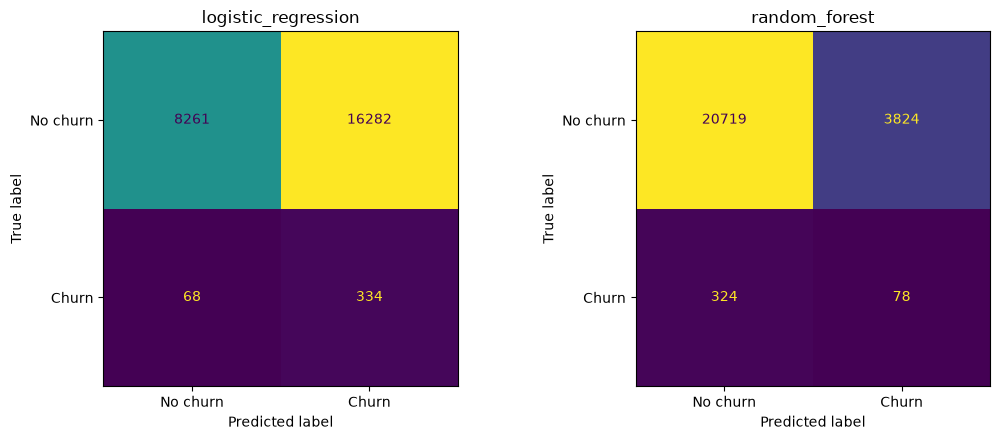

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (model_name, pipeline) in zip(axes, pipelines.items()):
    predicted_labels = (pipeline.predict_proba(X_test)[:, 1] >= bl.CLASSIFICATION_THRESHOLD).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted_labels, ax=ax, colorbar=False, display_labels=["No churn", "Churn"]
    )
    ax.set_title(model_name)

plt.tight_layout()
plt.show()


## 11. Baseline Comparison

In [14]:
comparison = results.pivot(index="model", columns="split", values=["roc_auc", "pr_auc", "recall", "precision"])
comparison


roc_auc               pr_auc               recall            precision           
split                    test validation      test validation      test validation      test validation
model                                                                                                  
logistic_regression  0.668745   0.619702  0.037655   0.028075  0.830846   0.741071  0.020101   0.020848
random_forest        0.521719   0.558722  0.017681   0.023185  0.194030   0.238839  0.019990   0.026368

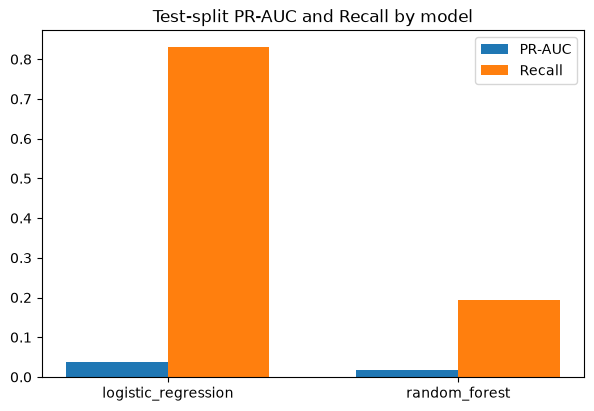

In [15]:
fig, ax = plt.subplots(figsize=(7, 4.5))
width = 0.35
models = list(pipelines.keys())
x = np.arange(len(models))

pr_auc_test = [results[(results["model"] == m) & (results["split"] == "test")]["pr_auc"].iloc[0] for m in models]
recall_test = [results[(results["model"] == m) & (results["split"] == "test")]["recall"].iloc[0] for m in models]

ax.bar(x - width / 2, pr_auc_test, width, label="PR-AUC")
ax.bar(x + width / 2, recall_test, width, label="Recall")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_title("Test-split PR-AUC and Recall by model")
ax.legend()
plt.show()


## 12. Conclusions and Next-Phase Recommendations

**What we built:** two leakage-safe baselines (Logistic Regression, Random
Forest) on a chronological train/validation/test split, evaluated with
imbalance-appropriate metrics at a fixed 0.5 threshold.

**How to read these numbers:** both models are working baselines, not
finished models. PR-AUC is low in absolute terms (well under the ~1-1.7%
random-guess floor would already look "low" by comparison, but should still
be read relative to that floor, not to 1.0), which is expected: the target
is extremely rare, the feature set is intentionally broad rather than
curated, and no tuning has been applied yet. Logistic Regression's
`class_weight="balanced"` setting produces high recall but very low
precision (it flags 60-70% of *all* rows as high-risk) -- useful as an
upper bound on recall, but not yet an actionable output. Random Forest is
more conservative (flags ~15% of rows) with correspondingly lower recall.

**Caveat carried over from Phase 4:** the underlying churn labels were
generated synthetically using each customer's full historical behavior as
an input to a churn-risk score. These baseline numbers should be read as a
methodology demonstration -- proof that the leakage-safe pipeline trains
and evaluates correctly end-to-end -- not as evidence of real-world
predictive power.

**Recommended next steps (Phase 6+):**
1. Hyperparameter tuning (grid/random search on validation) for both
   models, and likely gradient-boosted trees (XGBoost/LightGBM/CatBoost)
   as the project definition already scopes them in.
2. Threshold optimization on the validation split (this notebook
   deliberately fixed the threshold at 0.5) to trade precision vs. recall
   against a concrete business cost of a missed churn vs. a wasted
   retention action.
3. Feature selection / importance analysis -- 131 features for a ~1%
   positive class is a lot of capacity; narrowing this down should improve
   both performance and interpretability.
4. Model explainability (SHAP) once a stronger candidate model is chosen.


## Save Reproducible Outputs

Serialized pipelines to `models/`, and the results table to
`reports/baseline_results.csv`.


In [16]:
for model_name, pipeline in pipelines.items():
    saved_path = bl.save_pipeline(pipeline, f"{model_name}_baseline.joblib")
    print(f"Saved {model_name} -> {saved_path}")

results_path = bl.save_results(results)
print(f"Saved results -> {results_path}")


Saved logistic_regression -> /Users/dhananjaymandal/customer-retention-intelligence/models/logistic_regression_baseline.joblib
Saved random_forest -> /Users/dhananjaymandal/customer-retention-intelligence/models/random_forest_baseline.joblib
Saved results -> /Users/dhananjaymandal/customer-retention-intelligence/reports/baseline_results.csv
